# Laporan Praktikum 1 dan 2
Praktikum ini berisi 5 proses pemodelan machine learning yaitu EDA, Scrapping, Regresi Linear, Decision Tree dan Naive Bayes

## 1. Exploratory Data Analysis

### Import Library

In [1]:
# Maftuh Faisal_202431163
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import re

In [2]:
df = pd.read_csv('manga_sales.csv')
df.info() # Maftuh Faisal_202431163
df.head(10)

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   transaction_id    50000 non-null  int64  
 1   customer_id       49007 non-null  str    
 2   customer_name     50000 non-null  str    
 3   age               47504 non-null  str    
 4   age_group         47992 non-null  str    
 5   city              50000 non-null  str    
 6   email             46987 non-null  str    
 7   phone             47508 non-null  str    
 8   manga_title       50000 non-null  str    
 9   volume_no         47557 non-null  float64
 10  genre             50000 non-null  str    
 11  format            48068 non-null  str    
 12  platform          48018 non-null  str    
 13  payment_method    48030 non-null  str    
 14  unit_price        47472 non-null  str    
 15  quantity          47417 non-null  float64
 16  total_amount      47396 non-null  str    
 17  cust

,transaction_id,customer_id,customer_name,age,age_group,city,email,phone,manga_title,volume_no,...,unit_price,quantity,total_amount,customer_rating,purchase_date,delivery_days,is_returned,membership_tier,discount_percent,coupon_used
0,4784,CUST8189,SIMRAN DAS,NaN,Young Adult (18-24),Kolkata,simran.das@gmail.com,NaN,DR. STONE,23.0,...,349,1.0,349,4.4,06/08/22,12.0,False,Bronze,25,No
1,28779,CUST6564,Nikhil Reddy,13,Young Adult (18-24),Mumbai,NaN,9025371511,One Punch Man,3.0,...,299.00,4.0,1196,2.5,19 February 2020,8.0,1,NaN,0,Yes
2,37597,CUST2413,Shreya Chopra,NaN,NaN,Pune,shreya.chopra@gmail.com,9779267699,DEMON SLAYER,17.0,...,Rs.1299,1.0,1299,4.1,2021/07/06,7.0,True,NaN,0,none
3,44058,CUST8973,Arjun Joshi,27,Young Adult (18-24),Chennai,NaN,9966018593,Death Note,14.0,...,799,2.0,1598,4.9,27 September 2021,6.0,yes,Silver,20,Yes
4,49115,CUST4060,Pooja Joshi,150,Young Adult (18-24),Bangalore,pooja.joshi@gmail.com,971833,The Promised Neverland,16.0,...,349,5.0,1745,4.7,11/24/24,4.0,no,NaN,5,NaN
5,10408,CUST4547,Siddharth Das,25,Young Adult (18-24),Mumbai,siddharth.das@gmail.com,9685329623,One Punch Man,35.0,...,1499/-,NaN,NaN,4.2,03-03-2022,11.0,No,Bronze,15,Yes
6,2620,CUST2407,Priya Das,150,Young Adult (18-24),Hyderabad,priya.das@@gmail.com,9066815814,One Punch Man,38.0,...,199,3.0,597,3.6,August 2022,-1.0,no,Platinum,NaN,-
7,3378,CUST5476,Zara Chopra,17,Young Adult (18-24),Lucknow,zara.chopra@gmail.com,9903006244,Black Clover,1.0,...,199,1.0,199,3.0,2022-05-12T00:00:00Z,1.0,NaN,NaN,20,Yes
8,13924,CUST5131,sneha singh,23,Adult (25-30),Jaipur,sneha.singh@gmail.com,99582-83857,Mob Psycho 100,10.0,...,349,3.0,1047,NaN,15-01-2024,NaN,No,Gold,0,none
9,29946,CUST1117,Riya Iyer,24,Young Adult (18-24),Bangalore,NaN,9838348029,Chainsaw Man,2.0,...,499,5.0,NaN,2.7,18 August 2020,1.0,False,Bronze,20,No


## Adjusment of Variable Types & Data Cleaning

In [3]:

def extract_number(x):
    if pd.isna(x): return np.nan
    match = re.search(r'[-+]?\d*\.?\d+', str(x))
    return float(match.group()) if match else np.nan

num_cols = ['age', 'unit_price', 'quantity', 'total_amount', 'customer_rating', 'delivery_days']
for col in num_cols:
    if col in df.columns:
        df[col] = df[col].apply(extract_number)

cat_col = ['gender', 'city', 'genre', 'format', 'platform', 'payment_method', 'membership_tier']
for col in cat_col:
    if col in df.columns:
        df[col] = df[col].astype('category')

df.dtypes

transaction_id         int64
customer_id              str
customer_name            str
age                  float64
age_group                str
city                category
email                    str
phone                    str
manga_title              str
volume_no            float64
genre               category
format              category
platform            category
payment_method      category
unit_price           float64
quantity             float64
total_amount         float64
customer_rating      float64
purchase_date            str
delivery_days        float64
is_returned              str
membership_tier     category
discount_percent         str
coupon_used              str
dtype: object

In [4]:
df.describe(include="all") 

,transaction_id,customer_id,customer_name,age,age_group,city,email,phone,manga_title,volume_no,...,unit_price,quantity,total_amount,customer_rating,purchase_date,delivery_days,is_returned,membership_tier,discount_percent,coupon_used
count,50000.000000,49007,50000,46471.000000,47992,50000,46987,47508,50000,47557.000000,...,47472.000000,47417.000000,47396.000000,45933.000000,45050,47483.000000,47921,41437,48055,29723
unique,NaN,8966,1946,NaN,9,38,1498,44646,138,NaN,...,NaN,NaN,NaN,NaN,10517,NaN,16,12,12,8
top,NaN,CUST9531,Tanvir Malhotra,NaN,Young Adult (18-24),Ahmedabad,harsh.singh@gmail.com,XXXXXXXXXX,Bleach,NaN,...,NaN,NaN,NaN,NaN,May 2023,NaN,True,Gold,10,none
freq,NaN,17,113,NaN,15449,4629,139,1502,1603,NaN,...,NaN,NaN,NaN,NaN,136,NaN,4741,6753,7905,9564
mean,26013.356000,NaN,NaN,23.429730,NaN,NaN,NaN,NaN,NaN,321.984187,...,10707.727729,328.601535,12807.045166,3.821536,NaN,317.331782,NaN,NaN,NaN,NaN
std,14444.341905,NaN,NaN,26.181798,NaN,NaN,NaN,NaN,NaN,1714.346327,...,99776.176607,1775.353514,103689.216685,1.648106,NaN,1732.943193,NaN,NaN,NaN,NaN
min,1000.000000,NaN,NaN,-30.000000,NaN,NaN,NaN,NaN,NaN,-40.000000,...,-1499.000000,-5.000000,-7495.000000,-1.000000,NaN,-15.000000,NaN,NaN,NaN,NaN
25%,13487.750000,NaN,NaN,16.000000,NaN,NaN,NaN,NaN,NaN,9.000000,...,299.000000,2.000000,599.000000,3.100000,NaN,4.000000,NaN,NaN,NaN,NaN
50%,26035.500000,NaN,NaN,21.000000,NaN,NaN,NaN,NaN,NaN,20.000000,...,599.000000,3.000000,1495.000000,3.800000,NaN,8.000000,NaN,NaN,NaN,NaN
75%,38525.250000,NaN,NaN,26.000000,NaN,NaN,NaN,NaN,NaN,31.000000,...,999.000000,4.000000,2995.000000,4.500000,NaN,12.000000,NaN,NaN,NaN,NaN


## Detection and Treatment of Missing Values

In [5]:
df.isna().sum() 

transaction_id          0
customer_id           993
customer_name           0
age                  3529
age_group            2008
city                    0
email                3013
phone                2492
manga_title             0
volume_no            2443
genre                   0
format               1932
platform             1982
payment_method       1970
unit_price           2528
quantity             2583
total_amount         2604
customer_rating      4067
purchase_date        4950
delivery_days        2517
is_returned          2079
membership_tier      8563
discount_percent     1945
coupon_used         20277
dtype: int64

In [6]:

for col in cat_col:
    if col in df.columns:
        print(f"=== {col} ===")
        print(df[col].unique())
        print("\n")

=== city ===
['Kolkata', 'Mumbai', 'Pune', 'Chennai', 'Bangalore', ..., 'ahmedabad', 'chenna', 'dlhi', 'mumabi', 'bangalroe']
Length: 38
Categories (38, str): ['AHMEDABAD', 'Ahmedabad', 'BANGALORE', 'Bangalore', ..., 'lucknow', 'mumabi', 'mumbai', 'pune']


=== genre ===
['Thriller', 'Shonen', 'Fantasy', 'ACTION', 'Seinen', ..., 'fantasy', 'SHONEN', 'SLICE OF LIFE', 'Acton', 'horror']
Length: 35
Categories (35, str): ['ACTION', 'Action', 'Acton', 'FANTASY', ..., 'shojo', 'shonen', 'slice of life', 'thriller']


=== format ===
['Paperback', 'Box Set', 'Digital', 'Hardcover', 'Limited Edition', ..., '-', 'UNKNOWN', 'Unknown', 'unknown', 'na']
Length: 12
Categories (11, str): ['-', 'Box Set', 'Digital', 'Hardcover', ..., 'Unknown', 'na', 'none', 'unknown']


=== platform ===
['Amazon', 'MangaPlus Shop', '-', 'Flipkart', 'Book Depository', ..., 'Unknown', 'none', 'UNKNOWN', 'unknown', 'na']
Length: 14
Categories (13, str): ['-', 'Amazon', 'Book Depository', 'Crunchyroll Store', ..., 'Viz M

In [7]:

for col in df.columns:
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].mean())
    else:
        df[col] = df[col].fillna(df[col].mode()[0])

df.isna().sum()

transaction_id      0
customer_id         0
customer_name       0
age                 0
age_group           0
city                0
email               0
phone               0
manga_title         0
volume_no           0
genre               0
format              0
platform            0
payment_method      0
unit_price          0
quantity            0
total_amount        0
customer_rating     0
purchase_date       0
delivery_days       0
is_returned         0
membership_tier     0
discount_percent    0
coupon_used         0
dtype: int64

## Duplicate Data Treatment

In [8]:

print("Jumlah baris duplikat sebelum dihapus:", df.duplicated().sum())

df = df.drop_duplicates()
df.info()

Jumlah baris duplikat sebelum dihapus: 943
<class 'pandas.DataFrame'>
Index: 49057 entries, 0 to 49999
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   transaction_id    49057 non-null  int64   
 1   customer_id       49057 non-null  str     
 2   customer_name     49057 non-null  str     
 3   age               49057 non-null  float64 
 4   age_group         49057 non-null  str     
 5   city              49057 non-null  category
 6   email             49057 non-null  str     
 7   phone             49057 non-null  str     
 8   manga_title       49057 non-null  str     
 9   volume_no         49057 non-null  float64 
 10  genre             49057 non-null  category
 11  format            49057 non-null  category
 12  platform          49057 non-null  category
 13  payment_method    49057 non-null  category
 14  unit_price        49057 non-null  float64 
 15  quantity          49057 non-null  float64 


## Visualisasi Data

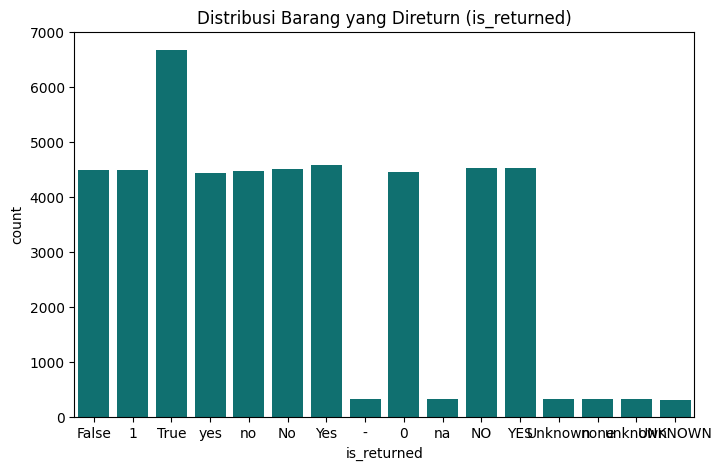

In [15]:
# Maftuh Faisal_202431163
plt.figure(figsize=(8, 5))
sns.countplot(x="is_returned", data=df, color='teal')
plt.title("Distribusi Barang yang Direturn (is_returned)")
plt.show()

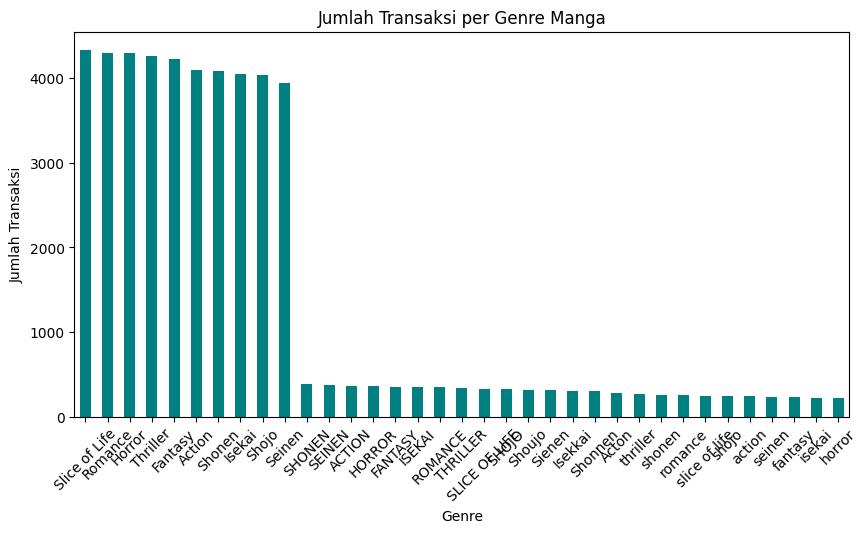

In [14]:

plt.figure(figsize=(10, 5))
df['genre'].value_counts().plot(kind='bar', color='teal', edgecolor='none')
plt.title("Jumlah Transaksi per Genre Manga")
plt.xlabel("Genre")
plt.ylabel("Jumlah Transaksi")
plt.xticks(rotation=45)
plt.show()

## Correlation of Variables

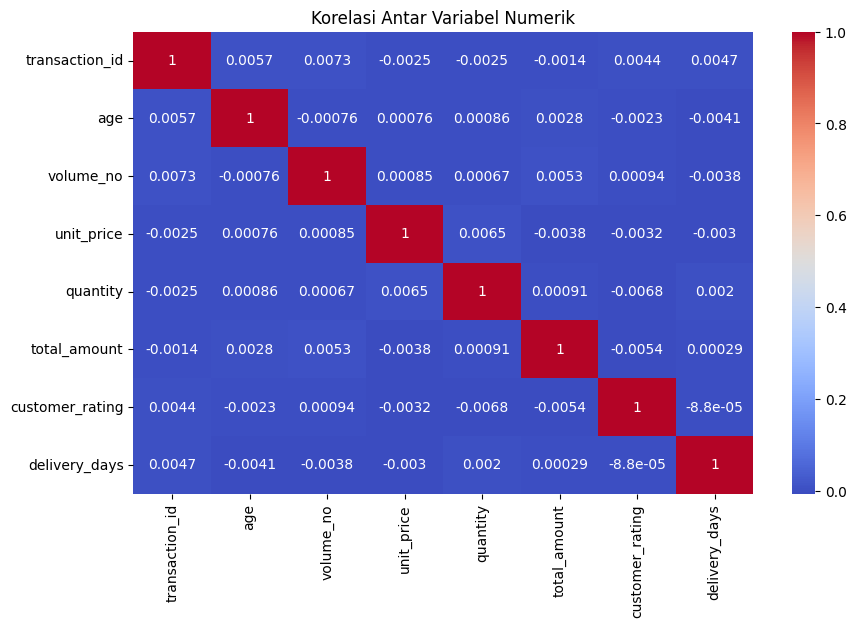

In [11]:
# Maftuh Faisal_202431163
num_df = df.select_dtypes(include=['float64', 'int64'])
plt.figure(figsize=(10, 6))
sns.heatmap(num_df.corr(), annot=True, cmap="coolwarm")
plt.title("Korelasi Antar Variabel Numerik")
plt.show()